In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import PchipInterpolator
from astropy import units as u
from astropy.constants import c
from dust_extinction.parameter_averages import F99

from utils import *

In [2]:
uv_phot = read_uvot_file(UV_FILE)

# Modjaz used UVOT UVW1, U, B, and V for the standard integration.
# UVW2 and UVM2 are retained for the optional far-UV calculation.
uv_phot = uv_phot[
    uv_phot["filter"].isin([
        "UVW2", "UVM2", "UVW1", "U", "B", "V"
    ])
].copy()

print(uv_phot.groupby("filter").size())
uv_phot.head()

filter
B       29
U       30
UVM2     1
UVW1    10
UVW2     2
V       29
dtype: int64


,time,filter,mag,magerr,source
0,0.1380,UVW2,20.77,0.18,Swift/UVOT
1,2.0329,UVW2,21.31,0.15,Swift/UVOT
2,2.0221,UVM2,21.30,0.20,Swift/UVOT
3,0.1339,UVW1,20.03,0.16,Swift/UVOT
4,2.0009,UVW1,19.54,0.06,Swift/UVOT


In [3]:
nir_phot = read_nir_file(NIR_FILE)
print(nir_phot.groupby("filter").size())
nir_phot.head()

filter
H     18
J     18
Ks    18
dtype: int64


,time,filter,mag,magerr,source
0,0.71,J,17.00,0.03,PAIRITEL
1,0.71,H,16.70,0.05,PAIRITEL
2,0.71,Ks,17.09,0.12,PAIRITEL
3,1.77,J,16.54,0.07,PAIRITEL
4,1.77,H,16.22,0.09,PAIRITEL


In [4]:
opt_phot = read_optical_file(OPT_FILE)

print(opt_phot.groupby("filter").size())
opt_phot.head()

filter
i'    17
r'    17
dtype: int64


,time,filter,mag,magerr,source
0,0.84,r',18.31,0.04,FLWO
1,0.84,i',18.17,0.03,FLWO
2,1.87,r',18.11,0.03,FLWO
3,1.87,i',17.86,0.03,FLWO
4,2.79,r',18.15,0.02,FLWO


         n  time_min  time_max  mag_min  mag_max
filter                                          
B       29    2.0265   38.5493    18.48    20.01
H       18    0.7100   35.6900    14.73    16.70
J       18    0.7100   35.6900    15.00    17.00
Ks      18    0.7100   35.6900    14.44    17.09
U       30    0.1359   38.7112    18.62    21.39
UVM2     1    2.0221    2.0221    21.30    21.30
UVW1    10    0.1339   24.0480    19.54    21.64
UVW2     2    0.1380    2.0329    20.77    21.31
V       29    2.0202   38.5438    17.31    18.55
i'      17    0.8400   29.8100    16.59    18.17
r'      17    0.8400   29.8100    16.95    18.31


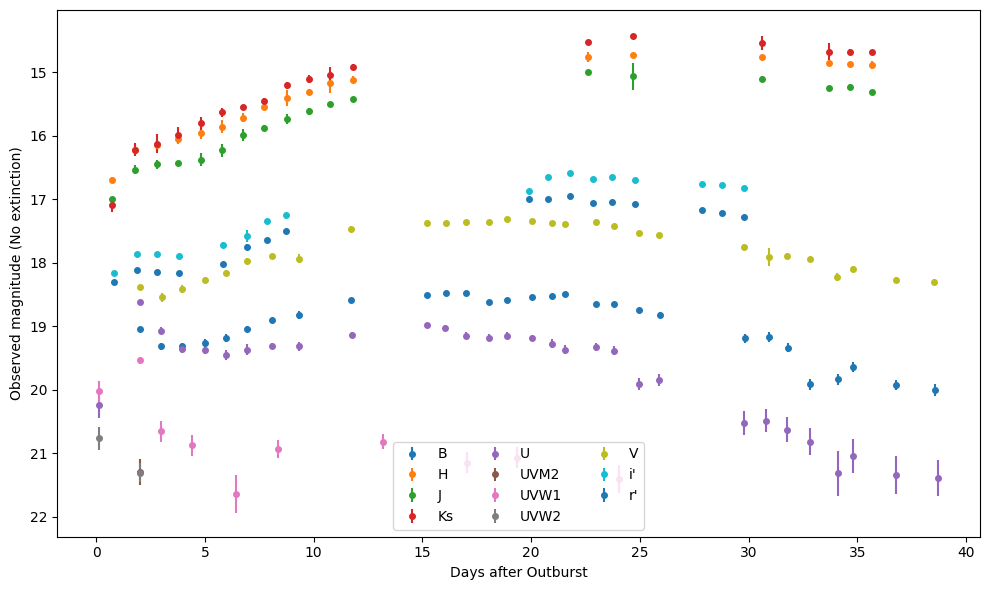

In [5]:
phot = pd.concat(
    [uv_phot, opt_phot, nir_phot],
    ignore_index=True,
)

phot = (
    phot[
        np.isfinite(phot["time"])
        & np.isfinite(phot["mag"])
    ]
    .sort_values(["filter", "time"])
    .reset_index(drop=True)
)

print(
    phot.groupby("filter").agg(
        n=("mag", "size"),
        time_min=("time", "min"),
        time_max=("time", "max"),
        mag_min=("mag", "min"),
        mag_max=("mag", "max"),
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

for filt, group in phot.groupby("filter"):
    ax.errorbar(
        group["time"],
        group["mag"],
        yerr=group["magerr"],
        fmt="o",
        ms=4,
        label=filt,
    )

ax.invert_yaxis()
ax.set_xlabel("Days after Outburst")
ax.set_ylabel("Observed magnitude (No extinction)")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

In [6]:
# Table 8 uses 0.8, 1.8, ..., 30.8 days.
m09_epochs = np.arange(
    0.8,
    30.81,
    1.0,
)

F_M09_reconstructed = np.full(
    len(m09_epochs),
    np.nan,
)

for i, epoch in enumerate(m09_epochs):
    # Standard UVW1-to-Ks result.
    sed = sed_at_epoch(
        epoch,
        phot,
        include_far_uv=False,
    )

    F_M09_reconstructed[i] = integrate_sed(
        sed,
        include_far_uv=False,
    )


distance_cm = (
    DISTANCE_MPC * u.Mpc
).to_value(u.cm)

L_M09_reconstructed = (
    4.0
    * np.pi
    * distance_cm**2
    * F_M09_reconstructed
)

logL_M09_reconstructed = np.log10(
    L_M09_reconstructed
)

print(
    "Reconstructed peak:"
    f" log10(L) = "
    f"{np.nanmax(logL_M09_reconstructed):.3f}"
)

print(
    "Peak epoch:",
    m09_epochs[
        np.nanargmax(logL_M09_reconstructed)
    ],
    "days",
)

Reconstructed peak: log10(L) = 42.229
Peak epoch: 21.8 days


In [8]:
epoch_far_uv = 1.8

sed_18_standard = sed_at_epoch(
    epoch_far_uv,
    phot,
    include_far_uv=False,
)

sed_18_far_uv = sed_at_epoch(
    epoch_far_uv,
    phot,
    include_far_uv=True,
)

F_18_standard = integrate_sed(
    sed_18_standard,
    include_far_uv=False,
)

F_18_far_uv = integrate_sed(
    sed_18_far_uv,
    include_far_uv=True,
)

L_18_standard = (
    4 * np.pi * distance_cm**2
    * F_18_standard
)

L_18_far_uv = (
    4 * np.pi * distance_cm**2
    * F_18_far_uv
)

print(
    "Day 1.8, UVW1-Ks:",
    np.log10(L_18_standard),
)

print(
    "Day 1.8, UVW2-Ks:",
    np.log10(L_18_far_uv),
)

Day 1.8, UVW1-Ks: 41.99443192988743
Day 1.8, UVW2-Ks: 42.050145194265625


In [10]:
filename = "data/SN2008D_Modjaz09.txt"

phase_M09 = []
logL_M09_BB = []
logL_M09_int = []

with open(filename, "r") as f:
    for line in f:
        cols = line.strip().split("\t")

        # Skip lines that are not data
        if len(cols) < 4:
            continue

        try:
            t = float(cols[0])
            L = float(cols[3].split("^")[0])
            L2 = float(cols[4].split("^")[0])
            

            phase_M09.append(t)
            logL_M09_BB.append(L)
            logL_M09_int.append(L2)

        except ValueError:
            continue
            
logL_M09_BB = np.asarray(logL_M09_BB)
logL_M09_int = np.asarray(logL_M09_int)
phase_M09 = np.asarray(phase_M09)


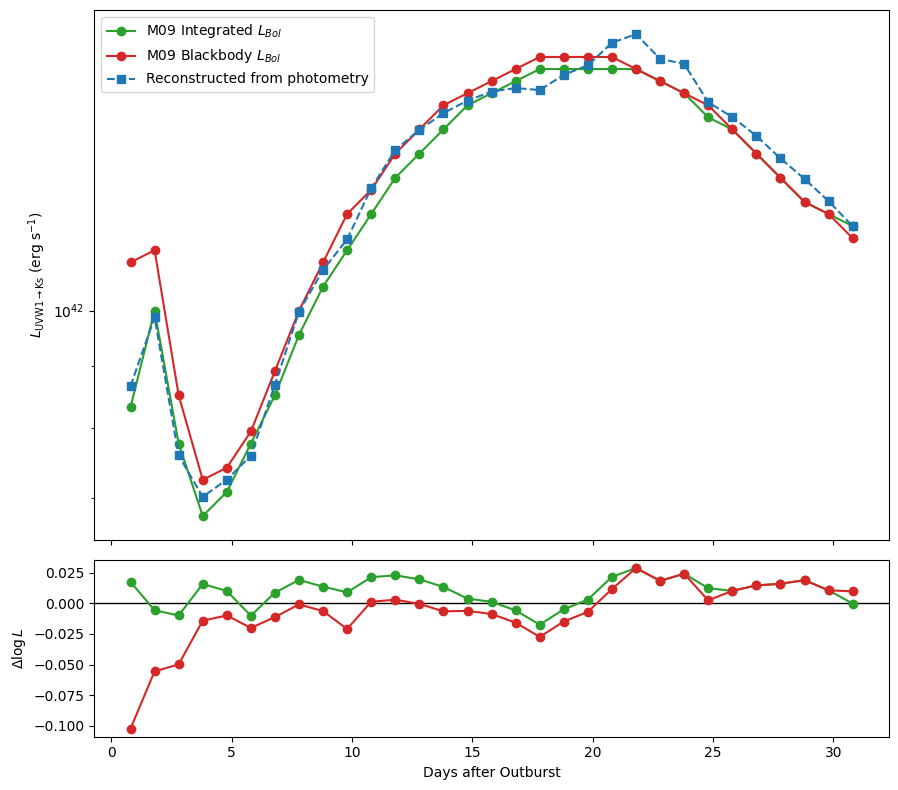

In [18]:
# Direct-integration column from Modjaz Table 8:
# log(L_UVW1->Ks), in erg/s.


residual_dex = (
    logL_M09_reconstructed
    - logL_M09_int
)

residual_dex2 = (
    logL_M09_reconstructed
    - logL_M09_BB
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

axes[0].plot(
    phase_M09,
    10**logL_M09_int,
    "o-",
    color="tab:green",
    label=r"M09 Integrated $L_{Bol}$",
)

axes[0].plot(
    phase_M09,
    10**logL_M09_BB,
    "o-",
    color="tab:red",
    label=r"M09 Blackbody $L_{Bol}$",
)

axes[0].plot(
    phase_M09,
    L_M09_reconstructed,
    "s--",
    color="tab:blue",
    label="Reconstructed from photometry",
)

axes[0].set_yscale("log")
axes[0].set_ylabel(
    r"$L_{\rm UVW1\rightarrow Ks}$"
    r" (erg s$^{-1}$)"
)
axes[0].legend()

axes[1].axhline(
    0,
    color="black",
    lw=1,
)

axes[1].plot(
    phase_M09,
    residual_dex,
    "o-",
    color = "tab:green",
)

axes[1].plot(
    phase_M09,
    residual_dex2,
    "o-",
    color = "tab:red",
)

axes[1].set_xlabel(
    "Days after Outburst"
)
axes[1].set_ylabel(
    r"$\Delta\log L$"
)

plt.tight_layout()
plt.show()
